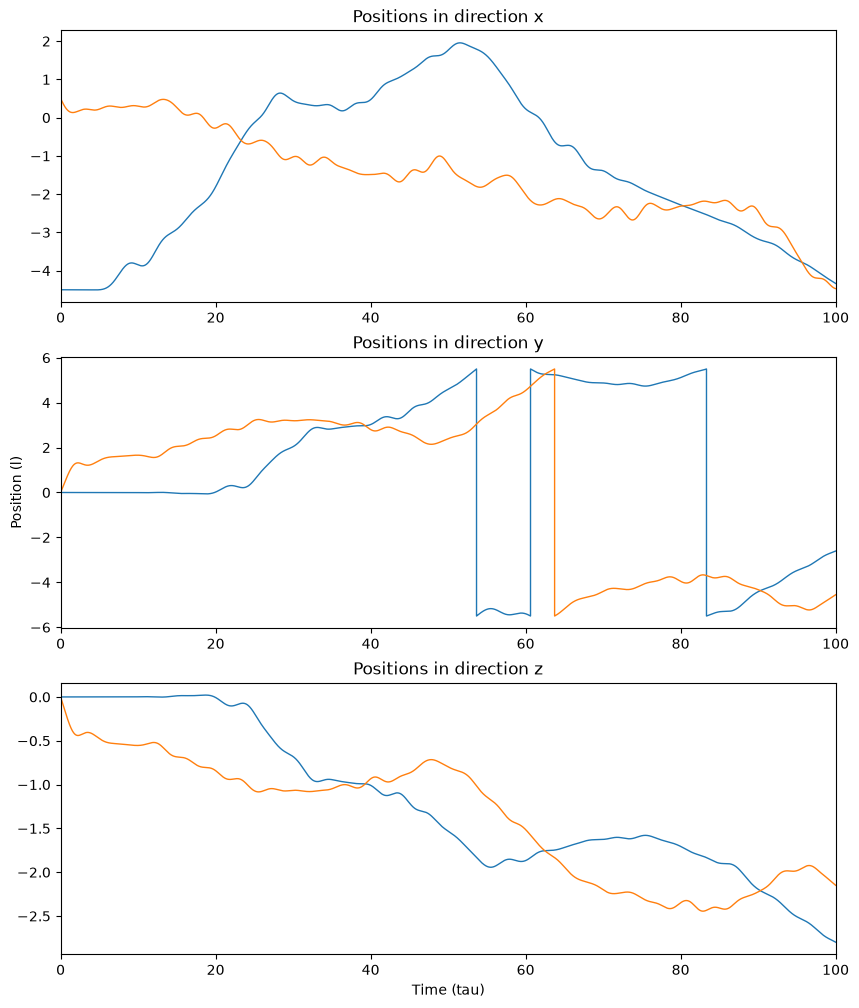

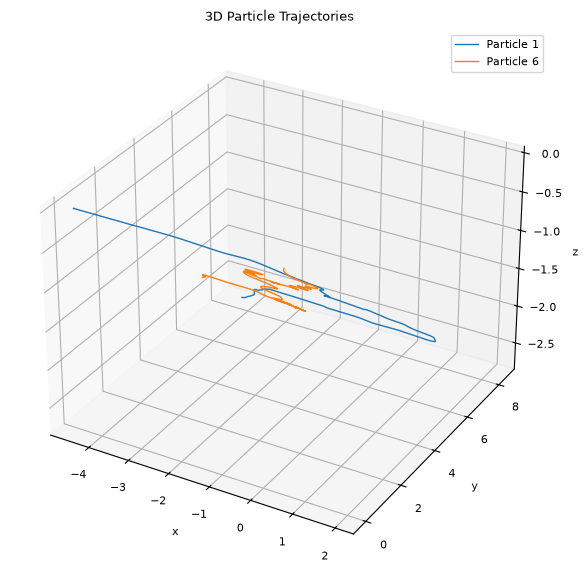

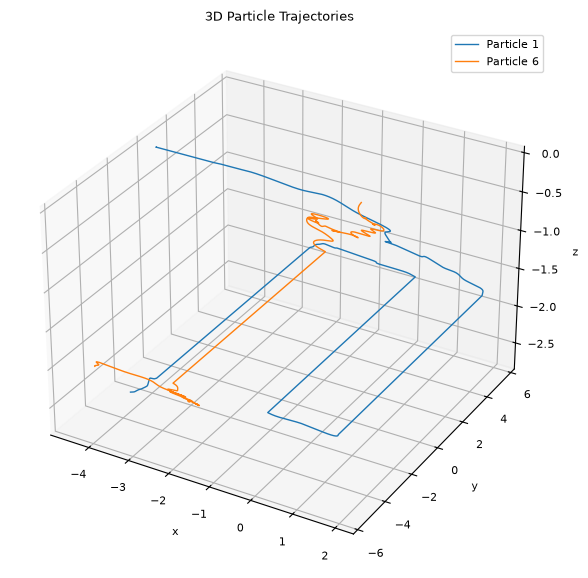

In [ ]:

"""
Task 5.1 (a)
1. Extend the force function and algorithm to 3D;
2. Add the periodic boundary condition to force function and position update;
3. Run the simulation for N = 11 and time over 100 tau, and visualized the trajectory of particle 1 and 6;
4. Plot the trajectory of center of mass over time;
5. Calculate the total energy over time.
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl            # A more complex but flexible bundle
from mpl_toolkits.mplot3d import Axes3D

"""
1. Extend the force function and algorithm to 3D;
2. Add the periodic boundary condition to force function and position update;
"""

k = 1
m = 1
l = 1
epsilon = k * l**2                                      # Energy unit for the harmonic chain
tau = np.sqrt(m / k)                                    # Time unit for the harmonic chain

L = 11 * l                                              # Length of the box in l
N = 11                                                  # Number of beads in the chain
t = 100                                                 # Total time in tau
dt = 0.001                                               # Time step in tau
n = int(round(t / dt))                                  # Number of time steps

r0 = np.array([[i*l - 0.5*L, 0, 0] for i in range(1, N+1)])
                                                        # Initial positions
p0 = np.zeros((N, 3))
p0[5, :] = np.array([-3/7, 6/7, -2/7]) * np.sqrt(m*epsilon)
                                                        # Initial momenta


# Define the force functions

def F_s(r1, r2, L):
    # force function for the first or the last particle
    # r1, r2 (float): WRAPPED positions of particles
    
    dij = r2 - r1
    dij = np.where(dij > L/2, dij - L, dij)
    dij = np.where(dij < -L/2, dij + L, dij)

    rij = np.linalg.norm(dij)
    
    return k * (rij - l) * dij / rij


def F_i(r1, r2, r3, L):
    # force function for intermediate particles
    # r1, r2, r3 (float): WRAPPED positions of particles

    return F_s(r2, r1, L) + F_s(r2, r3, L)


# Define the Verlet integration function

def verlet(r_0, p_0, N, t, dt, L):
    # Molecular dynamics simulation using Velocity-Verlet algorithm

    # r_0 (3*N 2D array): initial positions of particles
    # p_0 (3*N 2D array): initial momenta of particles
    # N (int): number of particles
    # t (float): total simulation time
    # dt (float): time step

    n = int(round(t / dt))                                          # Number of time steps
    r_u = np.zeros((N, 3, n+1))                                     # 3D array to store unwraped positions
    r_w = np.zeros((N, 3, n+1))                                     # 3D array to store wraped positions
    p = np.zeros((N, 3, n+1))                                       # 3D array to store momenta
    p_h = np.zeros((N, 3, n+1))                                     # 3D array to store half-step momenta
    r_u[:, :, 0] = r_0                                              # Set initial positions
    r_w[:, :, 0] = r_0
    p[:, :, 0] = p_0

    for j in range(n):
        # for each time step

        for i in range(N):
            # for each particle
            if i == 0:
                F = F_s(r_w[i, :, j], r_w[i+1, :, j], L)                           # Force on the first particle

            elif i == N - 1:
                F = F_s(r_w[i, :, j], r_w[i-1, :, j], L)                           # Force on the last particle

            else:
                F = F_i(r_w[i-1, :, j],r_w[i, :, j], r_w[i+1, :, j], L)            # Force on intermediate particles

            p_h[i, :, j + 1] = p[i, :, j] + 0.5 * dt * F                           # Update momentum at half step
            r_u[i, :, j + 1] = r_u[i, :, j] + dt * p_h[i, :, j + 1] / m            # Update unwrapped positions

        r_w[:, :, j + 1] = (r_u[:, :, j + 1] + L/2) % L - L/2                      # Update wrapped positions

        for i in range(N):
            # for each particle
            if i == 0:
                F_whole = F_s(r_w[i, :, j+1], r_w[i+1, :, j+1], L)                 # Force on the first particle

            elif i == N - 1:
                F_whole = F_s(r_w[i, :, j+1], r_w[i-1, :, j+1], L)                 # Force on the last particle

            else:
                F_whole = F_i(r_w[i-1, :, j+1],r_w[i, :, j+1], r_w[i+1, :, j+1], L)
                                                                                   # Force on intermediate particles
            p[i, :, j + 1] = p_h[i, :, j + 1] + 0.5 * dt * F_whole                 # Update momentum at full step
                    

    return r_u, r_w, p                                                             # Return arrays of positions, momenta, and end-to-end distances


"""
3. Run the simulation for N = 11 and time over 100 tau, and visualized the trajectory of particle 1 and 6;
"""

def plot_r(r, t, dt, l_):
    # Plot the positions of the particles over time
    # r (array with shape N, 3, n+1): position array of particles
    # t (float): time lenght of simulation
    # dt (float): time step
    # l_ (list): Indeces of particles to plot

    n = int(round(t / dt))                                          # Number of time steps
    time = np.linspace(0, t, n + 1)                                 # Time array

    fig, Ax = plt.subplots(3, 1, figsize = (10, 12))                                    # Generate axis in 3 rows, 1 column
    plt.rcParams.update({'font.size': 10})

    for j in range(3):
        # Plot the position vectors of each direction in a different graph
        for i in l_:
            # Plot the particles listed in l_ overtime
            Ax[j].plot(time, r[i, j, :], label=f'Particle {i + 1}', linewidth=1)
        A = ['x', 'y', 'z']
        Ax[j].set_title(f'Positions in direction {A[j]}')
        Ax[j].set_xlim(0, t)
    
    Ax[1].set_ylabel('Position (l)')
    Ax[2].set_xlabel('Time (tau)')
    fig.subplots_adjust(hspace=0.2)                                 # Adjust the space between subplots



def plot_3D(r, l_):
    fig = plt.figure(figsize=(9, 7))
    plt.rcParams.update({'font.size': 8})
    Ax = fig.add_subplot(111, projection='3d')

    for i in l_:
        Ax.plot(r[i, 0, :],
                r[i, 1, :],
                r[i, 2, :],
                label=f'Particle {i + 1}',
                linewidth=1)

    Ax.set_xlabel('x')
    Ax.set_ylabel('y')
    Ax.set_zlabel('z')
    Ax.set_title('3D Particle Trajectories')
    Ax.legend()

    plt.show()


r_u, r_w, p = verlet(r0, p0, N, t, dt, L)
plot_r(r_w, t, dt, [0, 5])
plot_3D(r_u, [0, 5])
plot_3D(r_w, [0, 5])


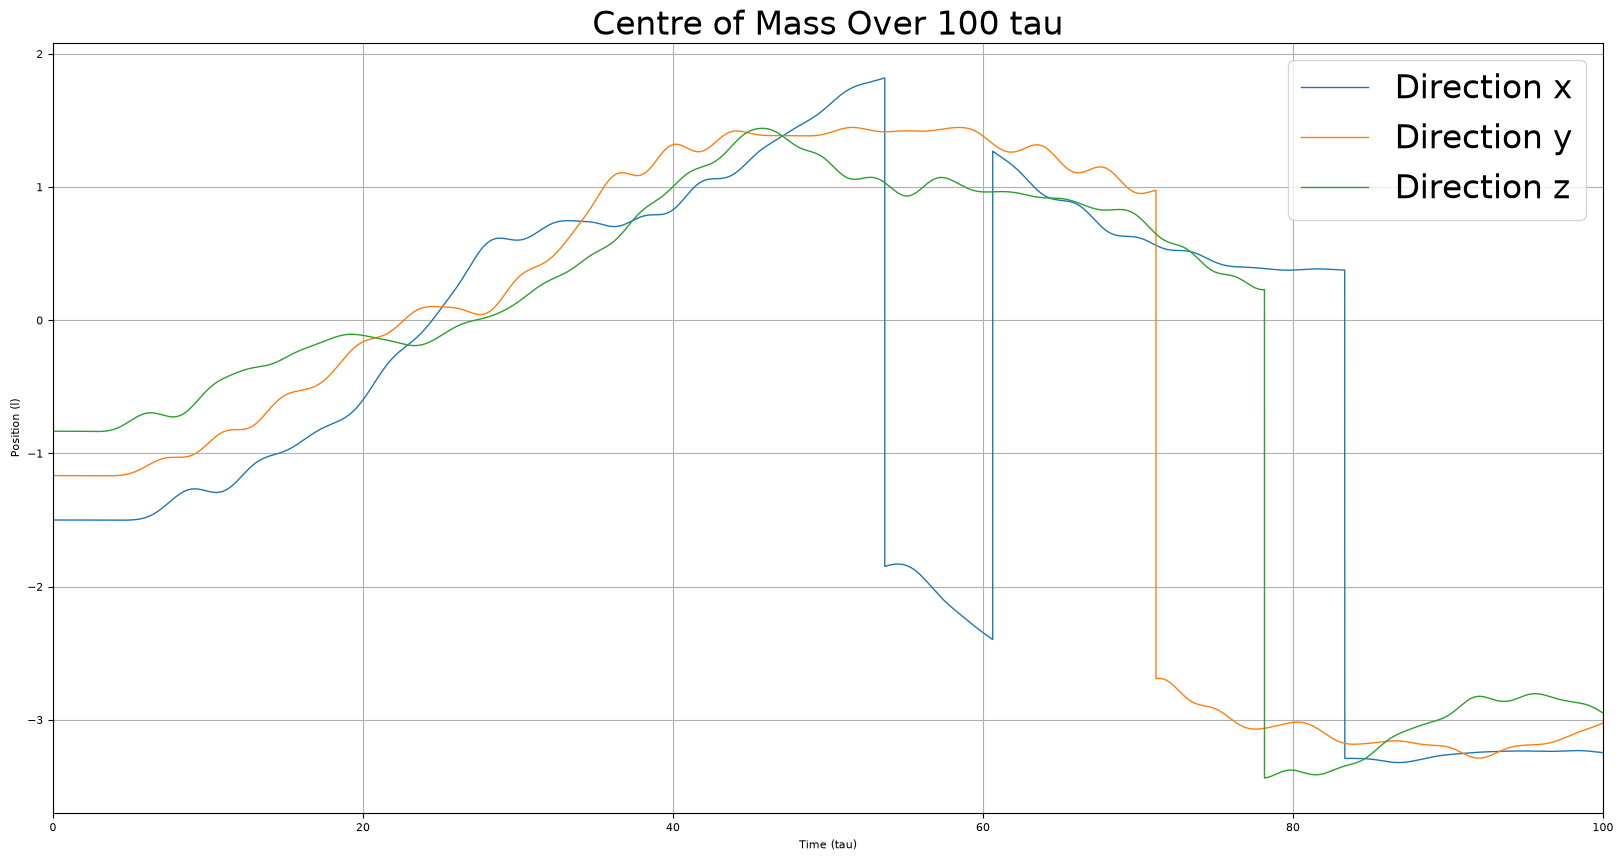

In [2]:
"""
4. Plot the trajectory of center of mass over time;
"""

r_com = np.mean(r_w, axis=1)
n = int(round(t / dt))                                          # Number of time steps
time = np.linspace(0, t, n + 1)                                 # Time array
A = ['x', 'y','z']

plt.figure(figsize=(20, 10))
for i in range(3):
    plt.plot(time, r_com[i, :], label=f'Direction {A[i]}', linewidth=1)             # Plot positions of each particle over time

plt.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 24,
    'axes.labelsize': 24,
    'xtick.labelsize': 24,
    'ytick.labelsize': 24,
    'legend.fontsize': 24
})

plt.xlim(0, t)
plt.title('Centre of Mass Over 100 tau')
plt.xlabel('Time (tau)')
plt.ylabel('Position (l)')
plt.legend()
plt.grid()
plt.show()


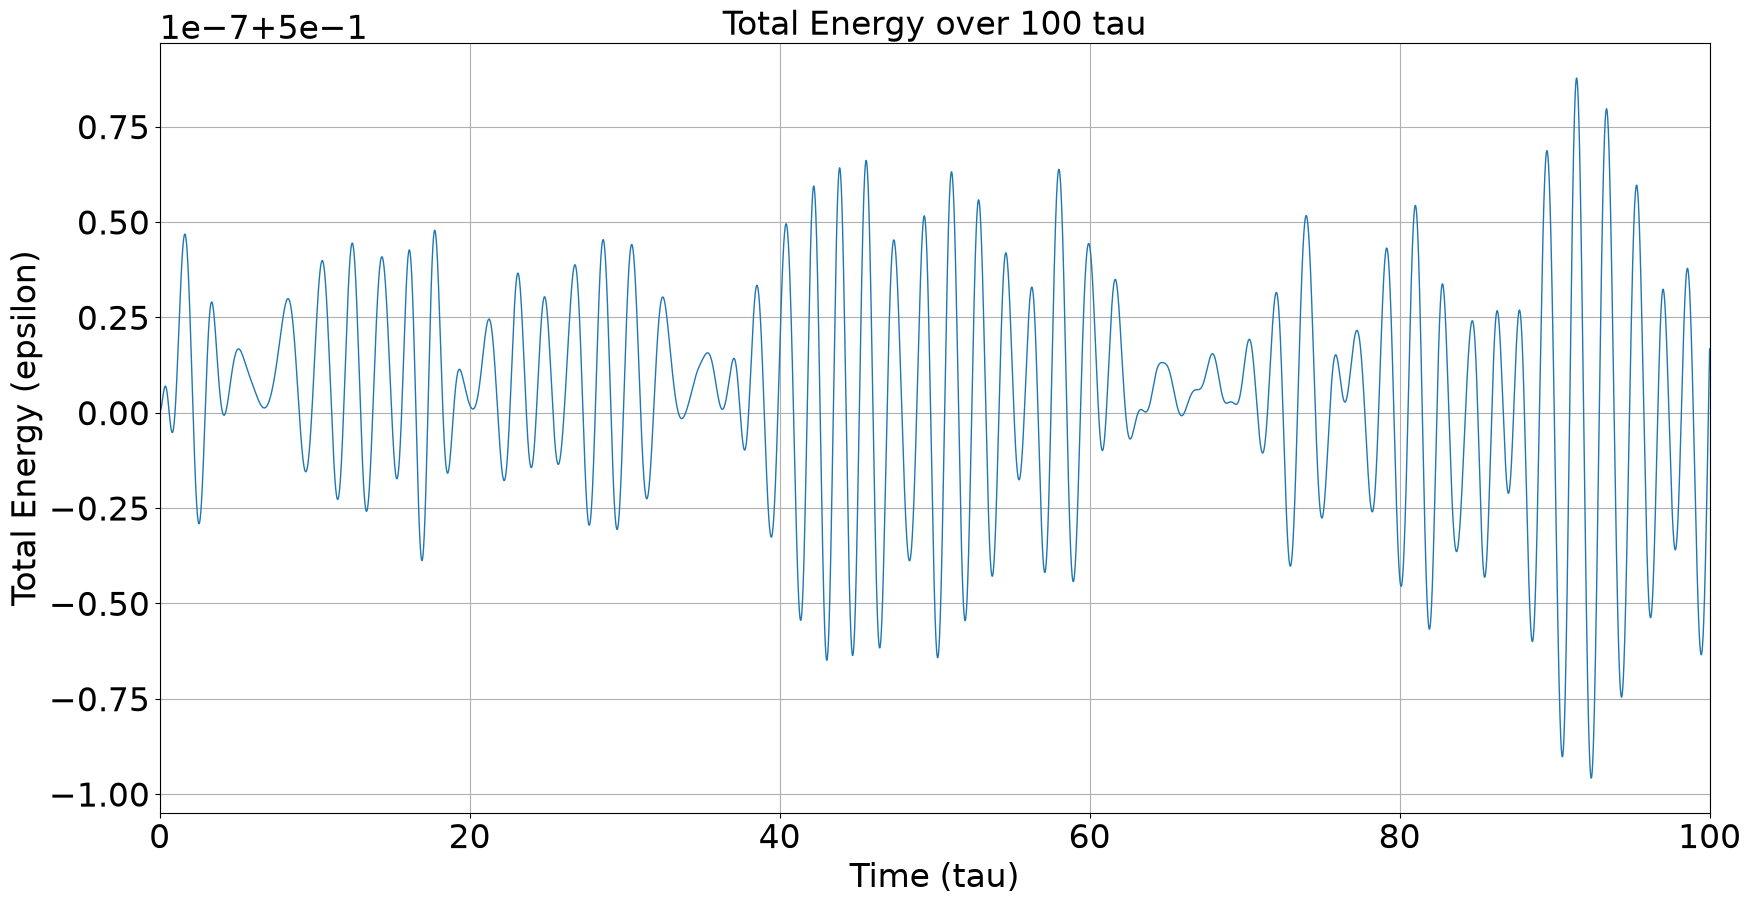

In [3]:
"""
5. Calculate the total energy over time.
"""


def total_energy(r, p, m, k, l, L):
    # Calculate the total energy of the harmonic chain

    # Kinetic energy
    K = np.sum(p**2, axis=(0, 1)) / (2 * m)

    # Calculate displacement vectors between neighbouring particles
    dij = r[1:, :, :] - r[:-1, :, :]

    # Apply minimum-image convention
    dij = np.where(dij > L/2, dij - L, dij)
    dij = np.where(dij < -L/2, dij + L, dij)

    # Calculate bond lengths
    rij = np.linalg.norm(dij, axis=1)

    # Potential energy
    U = 0.5 * k * np.sum((rij - l)**2, axis=0)

    # Total energy
    E = K + U

    return E

E_tot = total_energy(r_w, p, m, k, l, L)

plt.figure(figsize=(20, 10))
plt.plot(time, E_tot, linewidth=1)                      # Plot positions of total energy over time

plt.rcParams.update({'font.size': 20})
plt.xlim(0, t)
plt.title('Total Energy over 100 tau')
plt.xlabel('Time (tau)')
plt.ylabel('Total Energy (epsilon)')
plt.grid()
plt.show()

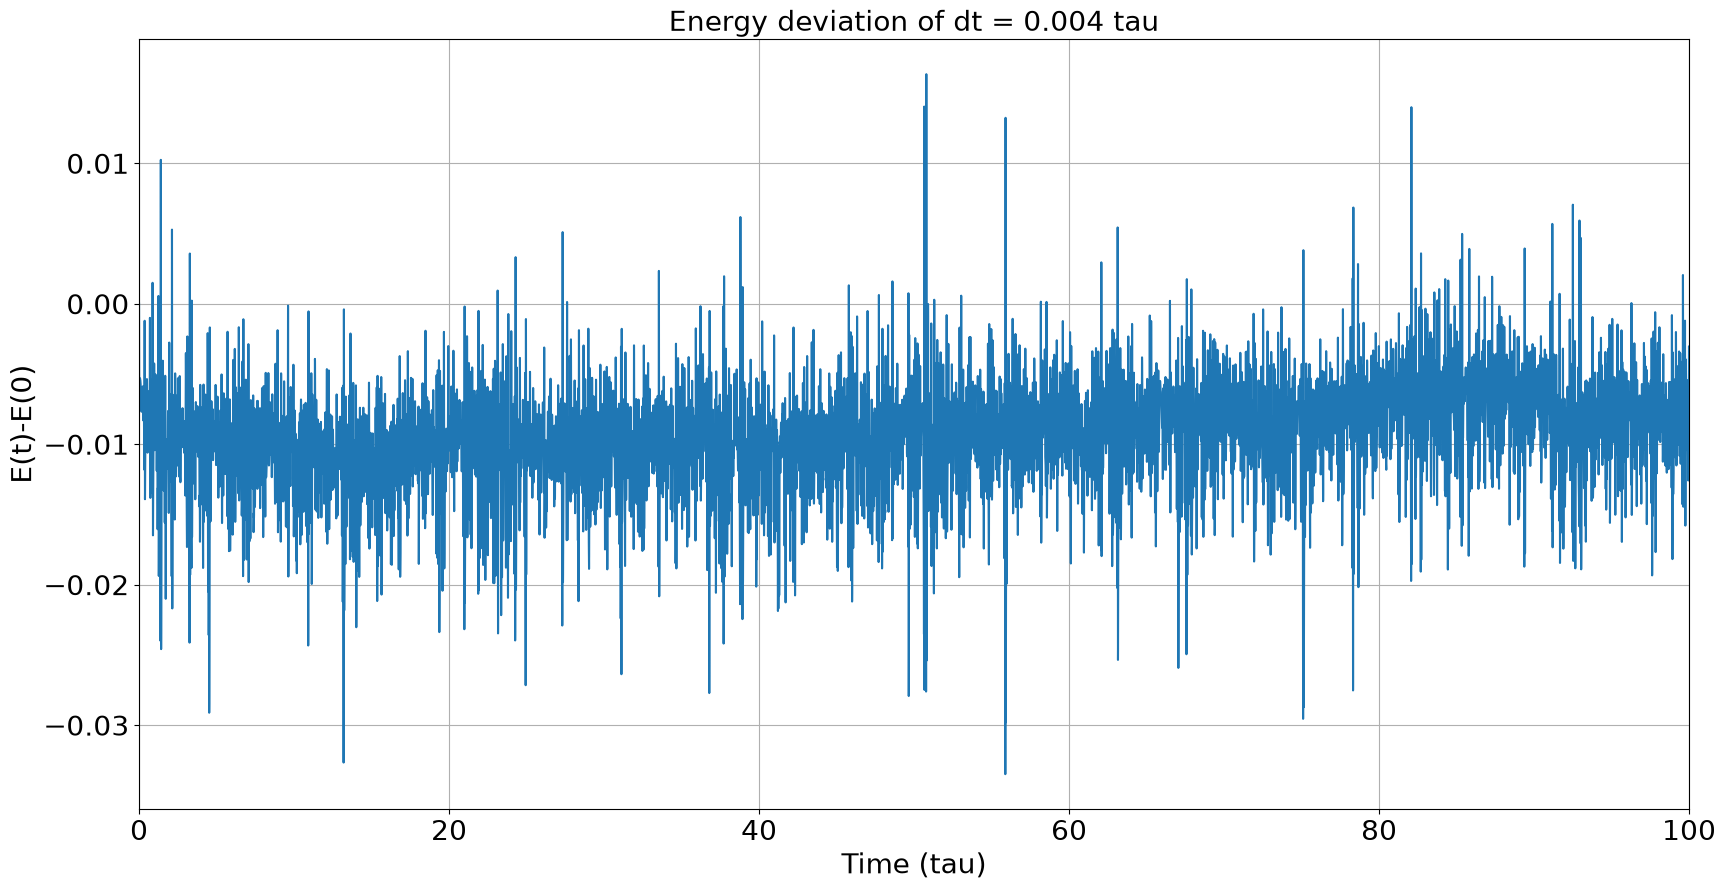

In [14]:
"""
Task 5.2 (a)
1. Compute the force equation under Lennard-Jones potential;
2. With t = 100 tau and dt = 0.002 tau, calculate and plot the total energy deviation over time;
3. Compare the total energy deviation for dt = 2 * dt, using same random seeds.
"""

"""
1. Compute the force equation under Lennard-Jones potential;
"""

kB = 1
m = 1
sigma = 1
epsilon = 1
tau = np.sqrt(m* sigma**2 / epsilon)
T = 1.5

L = 6 * sigma                                               # Length of the box in sigma
N = 64                                                      # Number of beads in the chain
t = 100                                                     # Total time in tau
dt = 0.002                                                  # Time step in tau
n = int(round(t / dt))                                      # Number of time steps

a = 1.5 * sigma
coords = np.arange(4) * a - L/2
X, Y, Z = np.meshgrid(coords, coords, coords, indexing='ij')
r0 = np.column_stack((X.ravel(), Y.ravel(), Z.ravel()))

rng = np.random.default_rng(seed=42)
p0 = rng.normal(
    loc=0.0,
    scale=np.sqrt(m * kB * T),
    size=(N, 3)
)


# Define the force functions

def F_(r_, a, L):
    # Force acting on particle a
    # r_: current particle positions, shape (N, 3)
    # a: index of the particle
    # L: length of the cubic box

    N = r_.shape[0]
    F = np.zeros(3)

    for i in range(N):
        if i == a:
            continue
        
        dr = r_[a] - r_[i]                  # Displacement vector
        dr -= L * np.round(dr / L)          # Minimum-image convention
        rij = np.linalg.norm(dr)            # Distance

        F += (24 * epsilon / rij**2) * (    # Lennard-Jones force
            2 * (sigma / rij)**12 - (sigma / rij)**6
        ) * dr

    return F



# Define the Verlet integration function

def verlet(r_0, p_0, N, t, dt, L):
    # Molecular dynamics simulation using Velocity-Verlet algorithm

    # r_0: initial positions, shape (N, 3)
    # p_0: initial momenta, shape (N, 3)
    # N: number of particles
    # t: total simulation time
    # dt: time step
    # L: length of the cubic box

    n = int(round(t / dt))

    r_u = np.zeros((N, 3, n+1))     # Unwrapped positions
    r_w = np.zeros((N, 3, n+1))     # Wrapped positions
    p = np.zeros((N, 3, n+1))       # Momenta
    p_h = np.zeros((N, 3, n+1))     # Half-step momenta

    # Set initial conditions
    r_u[:, :, 0] = r_0
    r_w[:, :, 0] = r_0
    p[:, :, 0] = p_0

    for j in range(n):

        F = np.array([F_(r_w[:, :, j], i, L) for i in range(N)])    # Calculate forces at the current positions

        p_h[:, :, j+1] = p[:, :, j] + 0.5 * dt * F                  # Update momenta at half step
        r_u[:, :, j+1] = r_u[:, :, j] + dt * p_h[:, :, j+1] / m     # Update unwrapped positions
        r_w[:, :, j+1] = (r_u[:, :, j+1] + L/2) % L - L/2           # Update wrapped positions
        F_whole = np.array([F_(r_w[:, :, j+1], i, L) for i in range(N)])
                                                                    # Calculate forces at the new positions
        p[:, :, j+1] = p_h[:, :, j+1] + 0.5 * dt * F_whole          # Update momenta at full step

    return r_u, r_w, p


"""
2. With t = 100 tau and dt = 0.002 tau, calculate and plot the total energy deviation over time;
"""


def energy(r, p, N, L):
    # Calculate total energy of the system
    
    K = np.sum(p**2) / (2 * m)                          # Kinetic energy
    U = 0.0                                             # Potential energy

    for i in range(N):
        for j in range(i+1, N):

            dr = r[i] - r[j]
            dr -= L * np.round(dr / L)
            rij = np.linalg.norm(dr)

            U += 4 * epsilon * (
                (sigma / rij)**12 - (sigma / rij)**6
            )

    return K + U

r_u, r_w, p = verlet(r0, p0, N, t, dt, L)
E = np.zeros(n+1)

for j in range(n+1):
    E[j] = energy(r_w[:, :, j], p[:, :, j], N, L)

E_1 = E - E[0]
time = np.arange(n+1) * dt

plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'legend.fontsize': 20
})


plt.figure(figsize=(20, 10))
plt.plot(time, E_1)
plt.title('Energy deviation of dt = 0.004 tau')
plt.xlabel("Time (tau)")
plt.ylabel("E(t)-E(0)")
plt.grid()
plt.xlim(0, t)
plt.show()



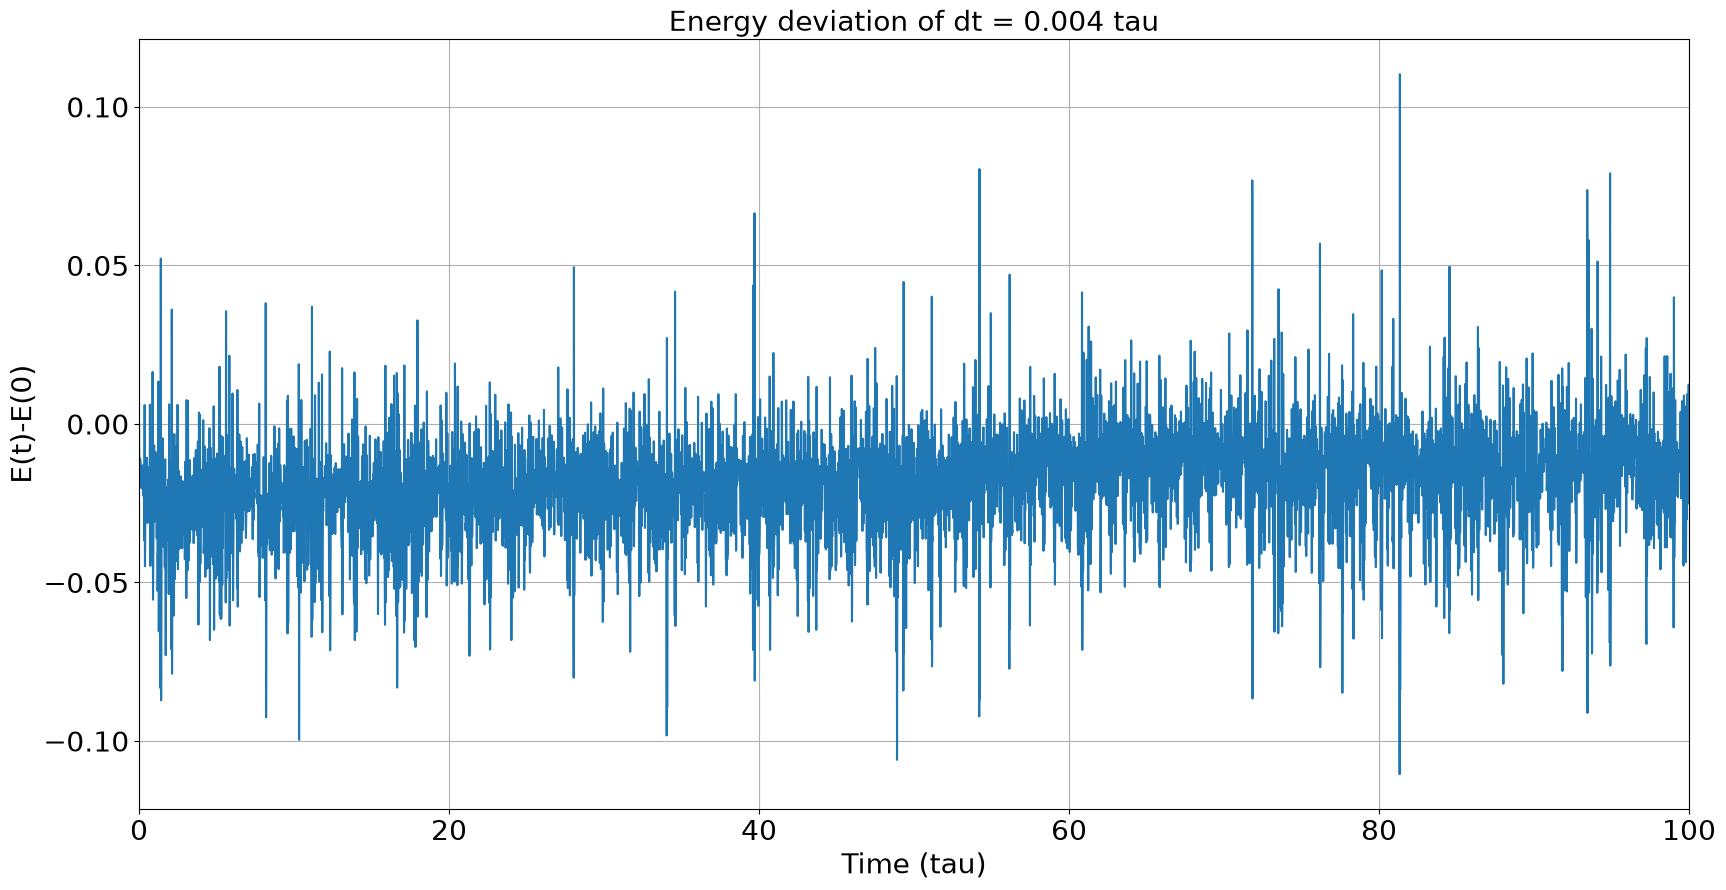

In [17]:
"""
3. Compare the total energy deviation for dt = 2 * dt, using same random seeds.
"""

dt = 0.004
n = int(round(t / dt))

r_u, r_w, p = verlet(r0, p0, N, t, dt, L)

E = np.zeros(n+1)

for j in range(n+1):
    E[j] = energy(r_w[:, :, j], p[:, :, j], N, L)

E_2 = E - E[0]
time = np.arange(n+1) * dt

plt.figure(figsize=(20, 10))
plt.plot(time, E_2)
plt.title('Energy deviation of dt = 0.004 tau')
plt.xlabel("Time (tau)")
plt.ylabel("E(t)-E(0)")
plt.grid()
plt.xlim(0, t)
plt.show()
